# Audio Emotion Recognition on CREMA-D

This notebook classifies six emotions from audio using
Mel-spectrograms and an ImageNet-pretrained ResNet18.

Training, validation, and test sets contain separate speakers.
The best model is selected using validation Macro-F1.



## Mount Google Drive and Locate Project Files

Connect Google Drive and locate the audio folder and split CSV files.
Check the number of WAV files and whether a GPU is available.

In [ ]:
from google.colab import drive
from pathlib import Path
import torch

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/affective computing")
AUDIO_DIR = BASE / "AudioWAV"

assert BASE.exists(), f"Project folder not found: {BASE}"
assert AUDIO_DIR.exists(), f"Audio folder not found: {AUDIO_DIR}"
assert (BASE / "train.csv").exists(), "train.csv not found"
assert (BASE / "test.csv").exists(), "test.csv not found"

wav_files = sorted(AUDIO_DIR.rglob("*.wav"))

print("Project folder:", BASE)
print("WAV files:", len(wav_files))
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/affective computing
WAV files: 7462
GPU available: True
GPU: Tesla T4


## Match Audio Files to Metadata

Construct the expected audio filenames from speaker, sentence,
emotion, and intensity information. Match each sample to its audio
path and resolve the known filename mismatch.

Verify that training and test speakers do not overlap.
Audio files not referenced in the CSV files are excluded.

In [ ]:
import pandas as pd

emotion_codes = {
    "Anger": "ANG",
    "Disgust": "DIS",
    "Fear": "FEA",
    "Happy": "HAP",
    "Neutral": "NEU",
    "Sad": "SAD",
}

intensity_codes = {
    "Unspecified": "XX",
    "High": "HI",
    "Medium": "MD",
    "Low": "LO",
}

# Check for duplicate filenames across audio folders
audio_index = {p.name: str(p) for p in wav_files}
assert len(audio_index) == len(wav_files), (
    "Duplicate WAV filenames found; check AudioWAV subfolders."
)

def prepare_split(csv_name):
    df = pd.read_csv(BASE / csv_name)

    # Remove leading and trailing whitespace from metadata
    for column in ["Label", "Convention", "Intesnsity"]:
        df[column] = df[column].str.strip()

    emotions = df["Label"].map(emotion_codes)
    intensities = df["Intesnsity"].map(intensity_codes)

    assert emotions.notna().all(), "Unknown emotion label"
    assert intensities.notna().all(), "Unknown intensity label"

    # Construct the expected audio filename from metadata
    df["filename"] = (
        df["Speaker"].astype(int).astype(str)
        + "_" + df["Convention"]
        + "_" + emotions
        + "_" + intensities
        + ".wav"
    )

    assert df["filename"].is_unique, "Duplicate CSV samples"

    # Resolve the known filename mismatch without renaming the audio
    df["actual_filename"] = df["filename"]
    expected = "1040_ITH_SAD_XX.wav"
    alternative = "1040_ITH_SAD_X.wav"

    if expected not in audio_index and alternative in audio_index:
        df.loc[
            df["filename"].eq(expected), "actual_filename"
        ] = alternative

    # Match each CSV sample to its audio path
    df["audio_path"] = df["actual_filename"].map(audio_index)

    missing = df["audio_path"].isna()
    print(f"{csv_name}: {len(df)} samples, {missing.sum()} missing")

    if missing.any():
        display(df.loc[missing, ["filename", "Label"]])

    return df

train_df = prepare_split("train.csv")
test_df = prepare_split("test.csv")

# Verify that training and test samples have no overlap
assert set(train_df["Speaker"]).isdisjoint(test_df["Speaker"])
assert set(train_df["filename"]).isdisjoint(test_df["filename"])
assert train_df["audio_path"].notna().all(), "Missing train audio"
assert test_df["audio_path"].notna().all(), "Missing test audio"

# Identify audio files that are not referenced in either CSV
used_files = set(train_df["actual_filename"]) | set(
    test_df["actual_filename"]
)
extra_files = sorted(set(audio_index) - used_files)

print("\nSpeaker overlap: 0")
print("Extra WAV files outside CSVs:", len(extra_files))
print(extra_files[:30])

train.csv: 5890 samples, 0 missing
test.csv: 1552 samples, 0 missing

Speaker overlap: 0
Extra WAV files outside CSVs: 20
['1016_IEO_NEU_XX (1).wav', '1016_IEO_SAD_HI (1).wav', '1016_IEO_SAD_LO (1).wav', '1016_IEO_SAD_MD (1).wav', '1016_IOM_ANG_XX (1).wav', '1016_IOM_DIS_XX (1).wav', '1016_IOM_FEA_XX (1).wav', '1016_IOM_HAP_XX (1).wav', '1016_IOM_NEU_XX (1).wav', '1016_IOM_SAD_XX (1).wav', '1016_ITH_ANG_XX (1).wav', '1016_ITH_DIS_XX (1).wav', '1016_ITH_FEA_XX (1).wav', '1016_ITH_HAP_XX (1).wav', '1016_ITH_NEU_XX (1).wav', '1016_ITH_SAD_XX (1).wav', '1034_MTI_FEA_XX (1).wav', '1034_MTI_HAP_XX (1).wav', '1034_TAI_DIS_XX (1).wav', '1036_DFA_SAD_XX (1).wav']


## Create a Speaker-Disjoint Validation Set

Reserve 20% of the training speakers for validation using gender
stratification and a fixed random seed of 42.

Verify that training, validation, and test sets have no speakers
in common. Keep the original test split unchanged.

In [ ]:
from sklearn.model_selection import train_test_split

# Obtain one gender label per training speaker using majority vote
speakers = (
    train_df.groupby("Speaker")["Gender"]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

# Split training speakers into training and validation groups
fit_speakers, val_speakers = train_test_split(
    speakers,
    test_size=0.20,
    stratify=speakers["Gender"],
    random_state=42,
)

fit_df = train_df[
    train_df["Speaker"].isin(fit_speakers["Speaker"])
].copy().reset_index(drop=True)

val_df = train_df[
    train_df["Speaker"].isin(val_speakers["Speaker"])
].copy().reset_index(drop=True)

# Verify speaker separation across all three subsets
fit_ids = set(fit_df["Speaker"])
val_ids = set(val_df["Speaker"])
test_ids = set(test_df["Speaker"])

assert fit_ids.isdisjoint(val_ids)
assert fit_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert len(fit_df) + len(val_df) == len(train_df)

for name, df in [
    ("Training", fit_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(df)} audio files, "
        f"{df['Speaker'].nunique()} speakers"
    )

print("\nSpeaker overlap: 0")

Training: 4667 audio files, 57 speakers
Validation: 1223 audio files, 15 speakers
Test: 1552 audio files, 19 speakers

Speaker overlap: 0


## Verify and Exclude the Silent Sample

Check the previously identified validation recording
1076_MTI_SAD_XX.wav and confirm that its amplitude is zero.

Exclude it from validation without deleting the original audio file.
The remaining validation set contains 1,222 samples.

In [ ]:
import soundfile as sf
import numpy as np

# Locate the previously identified silent sample
bad_filename = "1076_MTI_SAD_XX.wav"
mask = val_df["filename"].eq(bad_filename)

assert mask.sum() == 1, "Expected one matching validation sample"

# Verify that the sample is still completely silent
audio_path = val_df.loc[mask, "audio_path"].iloc[0]
audio, sr = sf.read(audio_path, dtype="float32")

assert audio.size > 0, "The audio file is empty"
assert np.isfinite(audio).all(), "The audio contains invalid values"

peak = float(np.max(np.abs(audio)))
print("Checked file:", bad_filename)
print("Peak amplitude:", peak)

assert peak == 0.0, (
    "This file is no longer silent; review it before excluding."
)

# Exclude the silent sample without deleting the original file
val_df = val_df.loc[~mask].copy().reset_index(drop=True)

print("\nTraining:", len(fit_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Checked file: 1076_MTI_SAD_XX.wav
Peak amplitude: 0.0

Training: 4667
Validation: 1222
Test: 1552


## Export Training and Validation Splits

Save the final training and validation metadata as CSV files.
The validation set contains 1,222 recordings from 15 speakers,
after excluding one silent recording.
Download the validation CSV for sharing with the project team.

In [ ]:
# Export the final training and validation splits
fit_df.to_csv(BASE / "audio_train.csv", index=False)
val_df.to_csv(BASE / "audio_validation.csv", index=False)

print("Validation samples:", len(val_df))
print("Validation speakers:", val_df["Speaker"].nunique())

# Download the validation CSV
from google.colab import files
files.download(str(BASE / "audio_validation.csv"))

Validation samples: 1222
Validation speakers: 15


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Inspect an Example Mel-Spectrogram

Load one training recording as mono audio at 16 kHz.
Compute a Mel-spectrogram with 128 Mel bands and convert it
to decibels relative to its maximum power.

Display the result to inspect the preprocessing output.
Plot labels and axes are not included in the model input.

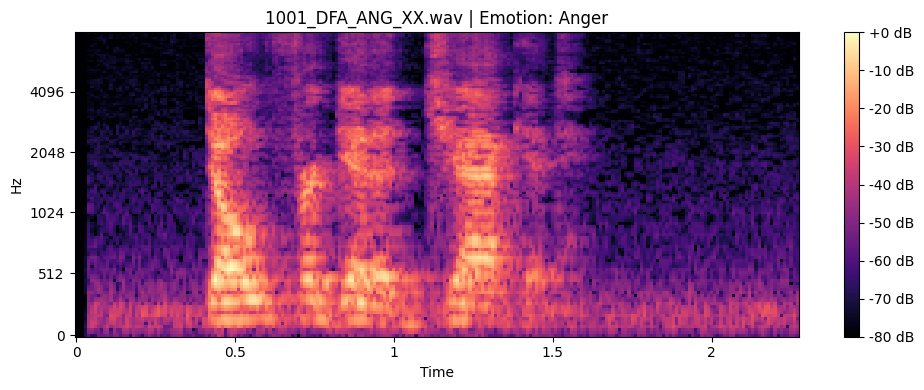

Duration: 2.28 seconds
Spectrogram shape: (128, 228)


In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load one training sample at a fixed sample rate
row = fit_df.iloc[0]
y, sr = librosa.load(row["audio_path"], sr=16000, mono=True)

assert y.size > 0, "Empty audio"
assert np.isfinite(y).all(), "Invalid audio values"
assert np.max(np.abs(y)) > 0, "Silent audio"

# Compute the Mel-spectrogram
mel = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_fft=512,
    win_length=400,
    hop_length=160,
    n_mels=128,
    power=2.0,
)

# Convert power to decibels relative to the maximum
mel_db = librosa.power_to_db(mel, ref=np.max, top_db=80)

# Display the spectrogram for inspection
plt.figure(figsize=(10, 4))
librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
)
plt.colorbar(format="%+2.0f dB")
plt.title(f'{row["filename"]} | Emotion: {row["Label"]}')
plt.tight_layout()
plt.show()

print("Duration:", round(len(y) / sr, 2), "seconds")
print("Spectrogram shape:", mel_db.shape)

## Generate and Cache Mel-Spectrograms

Convert each recording into a Mel-spectrogram using a 512-point
FFT, a 400-sample window, and a 160-sample hop.

Map the range from -80 to 0 dB to grayscale pixel values and resize
each spectrogram to 224 × 224 pixels. Save the images, labels,
filenames, speaker IDs, and preprocessing configuration.

Reuse existing cached files after checking that their metadata
and configuration match the current dataset splits.

In [ ]:
import shutil
import json
from PIL import Image
from tqdm.auto import tqdm

CACHE_DIR = BASE / "audio_features_v1"
LOCAL_CACHE = Path("/content/audio_features_v1")

CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_CACHE.mkdir(parents=True, exist_ok=True)

classes = ["Anger", "Disgust", "Fear", "Happy", "Neutral", "Sad"]
label_to_id = {name: i for i, name in enumerate(classes)}

config = {
    "sample_rate": 16000,
    "n_fft": 512,
    "win_length": 400,
    "hop_length": 160,
    "n_mels": 128,
    "db_min": -80,
    "image_size": [224, 224],
    "classes": classes,
}

def make_spectrogram(audio_path):
    # Read audio and convert stereo to mono if necessary
    y, sr = sf.read(audio_path, dtype="float32")
    if y.ndim == 2:
        y = y.mean(axis=1)

    if sr != 16000:
        y = librosa.resample(y, orig_sr=sr, target_sr=16000)

    assert y.size > 0, f"Empty audio: {audio_path}"
    assert np.isfinite(y).all(), f"Invalid audio: {audio_path}"
    assert np.max(np.abs(y)) > 0, f"Silent audio: {audio_path}"

    # Compute the Mel-spectrogram using fixed parameters
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=16000,
        n_fft=512,
        win_length=400,
        hop_length=160,
        n_mels=128,
        power=2.0,
    )
    mel_db = librosa.power_to_db(mel, ref=np.max, top_db=80)

    # Map decibels to grayscale pixels and resize for ResNet18
    pixels = np.rint(
        (np.clip(mel_db, -80, 0) + 80) / 80 * 255
    ).astype(np.uint8)

    image = Image.fromarray(pixels)
    image = image.resize((224, 224), Image.Resampling.BILINEAR)
    return np.asarray(image)

for split_name, df in [
    ("train", fit_df),
    ("validation", val_df),
    ("test", test_df),
]:
    local_file = LOCAL_CACHE / f"{split_name}.npz"
    saved_file = CACHE_DIR / f"{split_name}.npz"
    labels = df["Label"].map(label_to_id)
    assert labels.notna().all(), "Unknown emotion label"

    # Reuse an existing cache only if it matches the current split
    if saved_file.exists():
        shutil.copy2(saved_file, local_file)

        with np.load(local_file, allow_pickle=False) as data:
            assert json.loads(data["config"].item()) == config
            assert data["images"].shape == (len(df), 224, 224)
            assert np.array_equal(
                data["filenames"], df["filename"].to_numpy(dtype=str)
            ), "Cached filenames do not match"
            assert np.array_equal(
                data["labels"], labels.to_numpy(dtype=np.int64)
            ), "Cached labels do not match"
            assert np.array_equal(
                data["speakers"], df["Speaker"].to_numpy(dtype=np.int64)
            ), "Cached speakers do not match"

        print(f"{split_name}: existing cache verified ({len(df)} samples)")
        continue

    images = np.empty((len(df), 224, 224), dtype=np.uint8)

    for i, row in enumerate(
        tqdm(df.itertuples(index=False), total=len(df), desc=split_name)
    ):
        images[i] = make_spectrogram(row.audio_path)

    # Save features and metadata together to preserve sample order
    np.savez_compressed(
        local_file,
        images=images,
        labels=labels.to_numpy(dtype=np.int64),
        filenames=df["filename"].to_numpy(dtype=str),
        speakers=df["Speaker"].to_numpy(dtype=np.int64),
        config=np.array(json.dumps(config)),
    )

    # Copy the completed archive to Drive
    temporary_file = CACHE_DIR / f"{split_name}.npz.partial"
    shutil.copy2(local_file, temporary_file)
    temporary_file.replace(saved_file)

    print(f"{split_name}: saved {images.shape}")
    del images

print("\nAll spectrograms are ready.")

train: existing cache verified (4667 samples)
validation: existing cache verified (1222 samples)
test: existing cache verified (1552 samples)

All spectrograms are ready.


## Load Datasets and Initialize ResNet18

Load the cached Mel-spectrograms and prepare the data loaders.
Repeat each grayscale spectrogram across three channels and apply
ImageNet normalization. Initialize a pretrained ResNet18 and replace
its final layer to classify six emotions.

In [ ]:
import random
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

# Set random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class EmotionDataset(Dataset):
    def __init__(self, split):
        local_file = LOCAL_CACHE / f"{split}.npz"

        with np.load(local_file, allow_pickle=False) as data:
            self.images = data["images"]
            self.labels = data["labels"]
            self.filenames = data["filenames"]
            self.speakers = data["speakers"]
            self.config = json.loads(data["config"].item())

        # Use ImageNet normalization for the pretrained model
        self.mean = torch.tensor(
            [0.485, 0.456, 0.406]
        )[:, None, None]
        self.std = torch.tensor(
            [0.229, 0.224, 0.225]
        )[:, None, None]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        # Repeat the grayscale spectrogram across three channels
        x = torch.from_numpy(
            self.images[index].copy()
        ).float() / 255.0

        x = x.unsqueeze(0).repeat(3, 1, 1)
        x = (x - self.mean) / self.std

        label = torch.tensor(
            int(self.labels[index]), dtype=torch.long
        )
        return x, label

train_ds = EmotionDataset("train")
val_ds = EmotionDataset("validation")
test_ds = EmotionDataset("test")

classes = train_ds.config["classes"]
assert train_ds.config == val_ds.config == test_ds.config

# Verify speaker separation in the cached datasets
assert set(train_ds.speakers).isdisjoint(val_ds.speakers)
assert set(train_ds.speakers).isdisjoint(test_ds.speakers)
assert set(val_ds.speakers).isdisjoint(test_ds.speakers)

train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

# Load ImageNet weights and replace the classification layer
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

# Check input and output dimensions before training
images, labels = next(iter(train_loader))

model.eval()
with torch.no_grad():
    outputs = model(images.to(device))

print("Device:", device)
print("Classes:", classes)
print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(outputs.shape))
print("Dataset sizes:", len(train_ds), len(val_ds), len(test_ds))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]


Device: cuda
Classes: ['Anger', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad']
Input shape: (32, 3, 224, 224)
Output shape: (32, 6)
Dataset sizes: 4667 1222 1552


## Train ResNet18 and Save the Best Model

Fine-tune ResNet18 for up to 25 epochs using cross-entropy loss
and the AdamW optimizer. Use a lower learning rate for the
pretrained layers than for the new classification layer.

Select the best model using validation Macro-F1 and stop training
after five consecutive epochs without improvement. Save the best
model and training history to Google Drive.

In [ ]:
import time
from datetime import datetime
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# Create a separate output folder for this training run
RUN_DIR = BASE / "audio_runs" / datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = RUN_DIR / "best_resnet18.pt"

criterion = nn.CrossEntropyLoss()

# Use different learning rates for pretrained and new layers
optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for name, p in model.named_parameters()
                if not name.startswith("fc.")
            ],
            "lr": 1e-4,
        },
        {"params": model.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    true_labels, predictions = [], []

    with torch.set_grad_enabled(training):
        for x, y in tqdm(
            loader,
            desc="Train" if training else "Validation",
            leave=False,
        ):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)
            true_labels.extend(y.detach().cpu().tolist())
            predictions.extend(
                logits.argmax(1).detach().cpu().tolist()
            )

    return (
        total_loss / len(loader.dataset),
        accuracy_score(true_labels, predictions),
        f1_score(
            true_labels,
            predictions,
            labels=list(range(len(classes))),
            average="macro",
            zero_division=0,
        ),
    )

history = []
best_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, 26):
    start = time.time()

    train_loss, train_acc, train_f1 = run_epoch(
        train_loader, True
    )
    val_loss, val_acc, val_f1 = run_epoch(
        val_loader, False
    )
    scheduler.step(val_f1)

    # Save the metrics after every epoch
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
    })
    pd.DataFrame(history).to_csv(
        RUN_DIR / "history.csv", index=False
    )

    # Save the checkpoint with the highest validation Macro-F1
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        temporary_path = RUN_DIR / "best_resnet18.pt.partial"
        torch.save({
            "model_state_dict": model.state_dict(),
            "classes": classes,
            "config": train_ds.config,
            "epoch": epoch,
            "val_macro_f1": float(val_f1),
            "normalization_mean": [0.485, 0.456, 0.406],
            "normalization_std": [0.229, 0.224, 0.225],
        }, temporary_path)
        temporary_path.replace(BEST_PATH)
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_loss:.3f}, "
        f"accuracy: {train_acc:.3f} | "
        f"Val loss: {val_loss:.3f}, "
        f"accuracy: {val_acc:.3f}, "
        f"Macro-F1: {val_f1:.3f} | "
        f"{time.time() - start:.0f}s"
    )

    # Stop after five epochs without improvement
    if epochs_without_improvement >= 5:
        print("Early stopping")
        break

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation Macro-F1: {best_f1:.4f}")
print("Saved model:", BEST_PATH)

Train:   0%|          | 0/146 [00:00<?, ?it/s]

Validation:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 01 | Train loss: 1.330, accuracy: 0.469 | Val loss: 1.244, accuracy: 0.525, Macro-F1: 0.509 | 20s


Train:   0%|          | 0/146 [00:00<?, ?it/s]

Validation:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 02 | Train loss: 0.728, accuracy: 0.732 | Val loss: 1.381, accuracy: 0.527, Macro-F1: 0.527 | 22s


... (44 outputs left out)

Epoch 17 | Train loss: 0.002, accuracy: 0.999 | Val loss: 2.029, accuracy: 0.585, Macro-F1: 0.586 | 23s


Train:   0%|          | 0/146 [00:00<?, ?it/s]

Validation:   0%|          | 0/39 [00:00<?, ?it/s]

Epoch 18 | Train loss: 0.002, accuracy: 0.999 | Val loss: 2.058, accuracy: 0.580, Macro-F1: 0.579 | 23s
Early stopping

Best epoch: 13
Best validation Macro-F1: 0.5886
Saved model: /content/drive/MyDrive/affective computing/audio_runs/20261014_143230/best_resnet18.pt


## Evaluate the Best Model on the Test Set

Load the checkpoint selected using validation Macro-F1.
Evaluate it on the held-out test speakers and report accuracy,
Macro-F1, per-class precision and recall, and the confusion matrix.
Save each sample's predicted label and six class probabilities.

Checkpoint: /content/drive/MyDrive/affective computing/audio_runs/20261014_143230/best_resnet18.pt


Test:   0%|          | 0/49 [00:00<?, ?it/s]

Best epoch: 13
Test Accuracy: 0.6089
Test Macro-F1: 0.6084


,precision,recall,f1-score,support
Anger,0.726923,0.713208,0.720000,265.000000
Disgust,0.536965,0.520755,0.528736,265.000000
Fear,0.593750,0.501887,0.543967,265.000000
Happy,0.627530,0.584906,0.605469,265.000000
Neutral,0.602317,0.687225,0.641975,227.000000
Sad,0.570492,0.656604,0.610526,265.000000
accuracy,0.608892,0.608892,0.608892,0.608892
macro avg,0.609663,0.610764,0.608446,1552.000000
weighted avg,0.609843,0.608892,0.607625,1552.000000


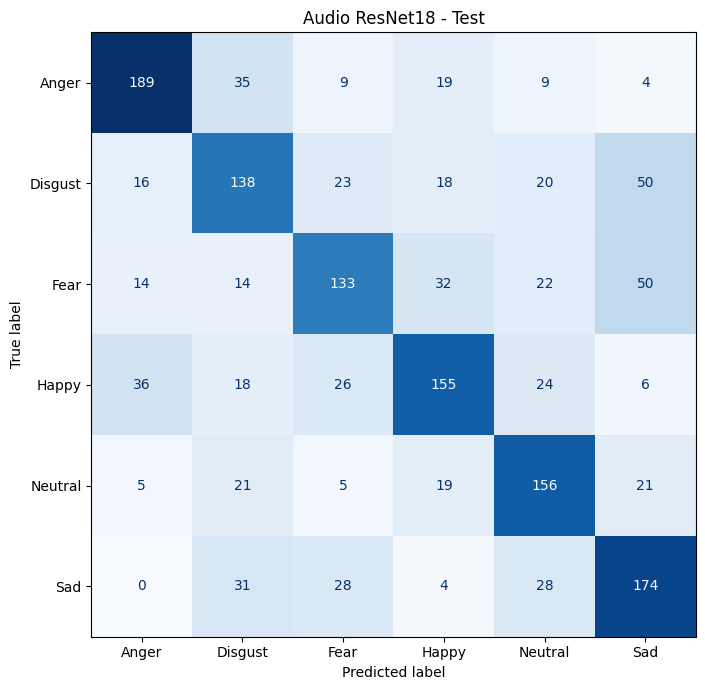

,filename,Speaker,true_label,predicted_label,correct,prob_Anger,prob_Disgust,prob_Fear,prob_Happy,prob_Neutral,prob_Sad
0,1005_DFA_ANG_XX.wav,1005,Anger,Anger,True,0.998165,1.641789e-08,0.001816,0.000013,5.912977e-07,5.296410e-06
1,1005_DFA_DIS_XX.wav,1005,Disgust,Disgust,True,0.012668,9.872954e-01,0.000002,0.000034,5.418632e-07,7.485411e-07
2,1005_DFA_FEA_XX.wav,1005,Fear,Fear,True,0.189220,2.460471e-06,0.809959,0.000795,5.792069e-07,2.395268e-05
3,1005_DFA_HAP_XX.wav,1005,Happy,Fear,False,0.121827,1.835618e-05,0.789282,0.087982,7.979557e-04,9.290372e-05
4,1005_DFA_NEU_XX.wav,1005,Neutral,Neutral,True,0.001082,3.527200e-04,0.000505,0.005828,8.668162e-01,1.254154e-01


Results saved in: /content/drive/MyDrive/affective computing/audio_runs/20261014_143230


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Load the best checkpoint from the current training run
print("Checkpoint:", BEST_PATH)
checkpoint = torch.load(
    BEST_PATH, map_location=device, weights_only=True
)

assert checkpoint["classes"] == classes
assert checkpoint["config"] == test_ds.config

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

probability_batches = []
true_batches = []

# Predict test samples in their original order
with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Test"):
        logits = model(x.to(device, non_blocking=True))
        probability_batches.append(
            torch.softmax(logits, dim=1).cpu().numpy()
        )
        true_batches.append(y.numpy())

probabilities = np.concatenate(probability_batches)
y_true = np.concatenate(true_batches)
y_pred = probabilities.argmax(axis=1)

# Verify sample order and probability values
assert np.array_equal(y_true, test_ds.labels)
assert np.isfinite(probabilities).all()
assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)

class_ids = list(range(len(classes)))

metrics = {
    "test_samples": int(len(y_true)),
    "best_epoch": int(checkpoint["epoch"]),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(
        y_true, y_pred,
        labels=class_ids,
        average="macro",
        zero_division=0,
    )),
}

print("Best epoch:", metrics["best_epoch"])
print(f"Test Accuracy: {metrics['accuracy']:.4f}")
print(f"Test Macro-F1: {metrics['macro_f1']:.4f}")

# Report per-class metrics
report = classification_report(
    y_true, y_pred,
    labels=class_ids,
    target_names=classes,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
display(report_df)

# Save labels and class probabilities for each test sample
predictions_df = pd.DataFrame({
    "filename": test_ds.filenames,
    "Speaker": test_ds.speakers,
    "true_label": [classes[i] for i in y_true],
    "predicted_label": [classes[i] for i in y_pred],
    "correct": y_true == y_pred,
})

for i, name in enumerate(classes):
    predictions_df[f"prob_{name}"] = probabilities[:, i]

predictions_df.to_csv(
    RUN_DIR / "test_predictions.csv", index=False
)
report_df.to_csv(RUN_DIR / "classification_report.csv")

with open(RUN_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Save and display the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    RUN_DIR / "confusion_matrix.csv"
)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Audio ResNet18 - Test")
plt.tight_layout()
plt.savefig(RUN_DIR / "confusion_matrix.png", dpi=200)
plt.show()

display(predictions_df.head())
print("Results saved in:", RUN_DIR)

## Results and Limitations

The best checkpoint was selected at epoch 13 using validation
Macro-F1, which reached 0.5886. Training stopped at epoch 18
after five consecutive epochs without improvement.

On the held-out test set of 1,552 recordings from 19 speakers,
the model achieved 60.89% accuracy and a Macro-F1 of 0.6084.

Training accuracy approached 100%, while validation accuracy
at the best epoch was 58.84%, indicating overfitting and limited
generalization to unseen speakers.

The exported predictions include the true label, predicted
label, and six softmax probabilities for each test recording.
These probabilities were not calibrated.